# 06 DERRETIMENTO BASAL LAGRANGIANO NAS PLATAFORMAS DA ASE, ESCALA ÓTIMA DA DIVERGÊNCIA, MANCHAS NEGATIVAS E FATORIAL DE INCERTEZA ESTRUTURAL

Este caderno apresenta a teoria física, a formulação numérica e os resultados do produto de derretimento basal ($m_b$, 2019–2025) sobre as plataformas de gelo do Mar de Amundsen (**Pine Island**, **Thwaites Oriental/TEIS**, **Crosson**, **Dotson** e **Cosgrove**), construído a partir de $4.574$ grânulos ATL06 r007 nas quatro estações austrais (DJF, MAM, JJA, SON):

$$m_b(x, y) = \text{SMB}(x, y) - \frac{DH}{Dt}(x, y) - H(x, y)\left(\nabla\cdot\mathbf{u}(x, y)\right)$$

---

## 1. Fundamentação Física e Comparação com o Estado da Arte (2014–2026)

A literatura de estimativa de derretimento basal por altimetria de satélite evoluiu ao longo de três gerações metodológicas:
1. **Primeira geração (ICESat/CryoSat-2 em grades de $1\text{--}10\text{ km}$; Moholdt et al., 2014; Paolo et al., 2023; Adusumilli et al., 2020):** Estabeleceu que a formulação Lagrangiana reduz a variância espúria de advecção em $\sim 50\%$, mas utilizou um único modelo de firn/SMB, máscaras estáticas de linha de aterramento e propagou apenas erros gaussianos formais;
2. **Segunda geração (DEMs estereofotogramétricos WorldView/REMA e CryoSat-2 *swath*; Shean et al., 2019; Zinck et al., 2023, 2026; Davison et al., 2023; Chartrand et al., 2024; Lowery et al., 2025, 2026):** Demonstrou que canais basais e zonas de cisalhamento concentram taxas extremas de fusão, mas que o desequilíbrio hidrostático por fendas basais (Vaughan et al., 2012) e aterramento transitório produz **faixas alternadas de ganho e perda aparente ($m_b < 0$)** com incerteza pontual de $\pm 8\text{ a }\pm 28\text{ m/ano}$ (Chartrand et al., 2024, Tabela 1);
3. **Comparador direto com ICESat-2 ATL06 na ASE (Meng et al., 2025, *Environ. Res. Lett.*, 20, 084016, período 2019–2023):** Meng et al. (2025) estimaram taxas médias para as plataformas da ASE, porém com cinco limitações estruturais que este trabalho resolve diretamente:
   - *(i)* Usaram um buffer fixo de $2\text{ km}$ na linha de aterramento de 2007–2009 (que inclui gelo em flexão na Dotson/Cosgrove e descarta gelo flutuante na Thwaites/Crosson);
   - *(ii)* Aplicaram um único modelo de firn (IMAU-FDM) e de SMB (RACMO2.3p2), omitindo a incerteza epistêmica entre modelos de firn (que mostramos pesar $3{,}6\text{ m/ano}$ na Pine Island);
   - *(iii)* Declararam apenas incerteza por desvio móvel local ($\pm 1{,}46\text{ m/ano}$ na PIG), $3\times$ menor que a incerteza total quando se incluem firn, agregação e velocidade;
   - *(iv)* Não validaram o produto contra radares de fase *in situ* (ApRES) nem contra radar aerotransportado (MCoRDS);
   - *(v)* Afirmaram coerência das anomalias com o ENSO sem corrigir os graus de liberdade pela forte autocorrelação induzida pelo filtro temporal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tab_final = pd.read_csv(DATA_DIR / "tabela_final_basal_ase.csv")
unc_v2 = pd.read_csv(DATA_DIR / "incerteza_estrutural_basal_resumo.csv")
cv_krig = pd.read_csv(DATA_DIR / "cv_interpolacao_basal.csv")
div_diag = pd.read_csv(DATA_DIR / "divergencia_escala_cv.csv")
vel_check = pd.read_csv(DATA_DIR / "velocidade_itslive_vs_measures.csv")
blue_spots = pd.read_csv(DATA_DIR / "blue_spots_resumo_por_unidade.csv")
check_refreeze = pd.read_csv(DATA_DIR / "open_check_8_recongelamento.csv")
ser_h = pd.read_csv(DATA_DIR / "serie_espessura_f090.csv")

tab_final.set_index("unidade").round(2)

,mb_mpa,sigma_estat,sigma_estrutural,sigma_total,fator_velocidade,area_medida_km2,area_inteira_km2,frac_medida,Gt_medido,sigma_Gt_medido,Gt_inteira_min,Gt_inteira_max,sigma_Gt_inteira
unidade,,,,,,,,,,,,,
Pine_Island,17.53,0.48,4.51,4.53,-0.61,3039.00,5232.25,0.58,48.86,12.64,82.80,84.12,21.77
Thwaites_TEIS,6.88,0.40,3.07,3.10,-0.50,764.75,1084.50,0.71,4.82,2.17,6.84,7.83,3.12
Crosson,8.76,0.25,1.19,1.22,-0.11,1950.75,3176.75,0.61,15.66,2.17,25.51,27.48,3.68
Dotson,6.66,0.17,0.74,0.76,0.03,3843.00,5741.25,0.67,23.46,2.67,35.05,43.23,5.72
Cosgrove,0.71,0.09,0.37,0.38,-0.30,2103.75,3041.25,0.69,1.37,0.74,1.97,2.41,1.09
TOTAL (sem TWGT),NaN,NaN,NaN,NaN,NaN,11701.25,18276.00,NaN,94.18,20.40,152.18,165.07,35.38


---
## 2. Séries de Espessura por Efeitos Fixos de Célula Material (GEMB vs. IMAU-FDM) e Seleção de Interpolador para $DH/Dt$

No Passo 5 da cadeia basal (`run_thickness_ase.py`), cada segmento sobre a máscara hidrostática é convertido em espessura equivalente $H = 9{,}336\,(h_{\text{mar}} - \text{FAC})$ usando dois modelos independentes de conteúdo de ar do firn interpolados por triangulação de Delaunay no espaço e linearmente no tempo: **GEMB v1.5** (2018–2025) e **IMAU-FDM v1.2A** (2018–2023,98). A série trimestral $s_k$ ($K = 28$ estações-ano) é extraída pelo modelo de efeitos fixos de célula material (`fe_series`), eliminando analiticamente o plano topográfico de cada célula de $500\text{ m}$.

Como as células materiais com suporte temporal robusto ($\ge 8$ passagens e $\ge 3$ anos) cobrem $21\text{--}40\%$ da área das plataformas ao longo das trilhas, avaliamos por **Validação Cruzada Espacial em 10 Dobras de Blocos de $5\text{ km}$ (`cv_interpolacao_basal.csv`)** a interpolação contínua de $DH/Dt$ entre 5 kernels gaussianos ($L = 1, 2, 3, 5, 8\text{ km}$) e **Krigagem Ordinária local** ($48$ vizinhos, covariância exponencial ajustada ao semivariograma empírico da plataforma com pepita heterocedástica $\sigma_i^2 + c_{\text{extra}}$):

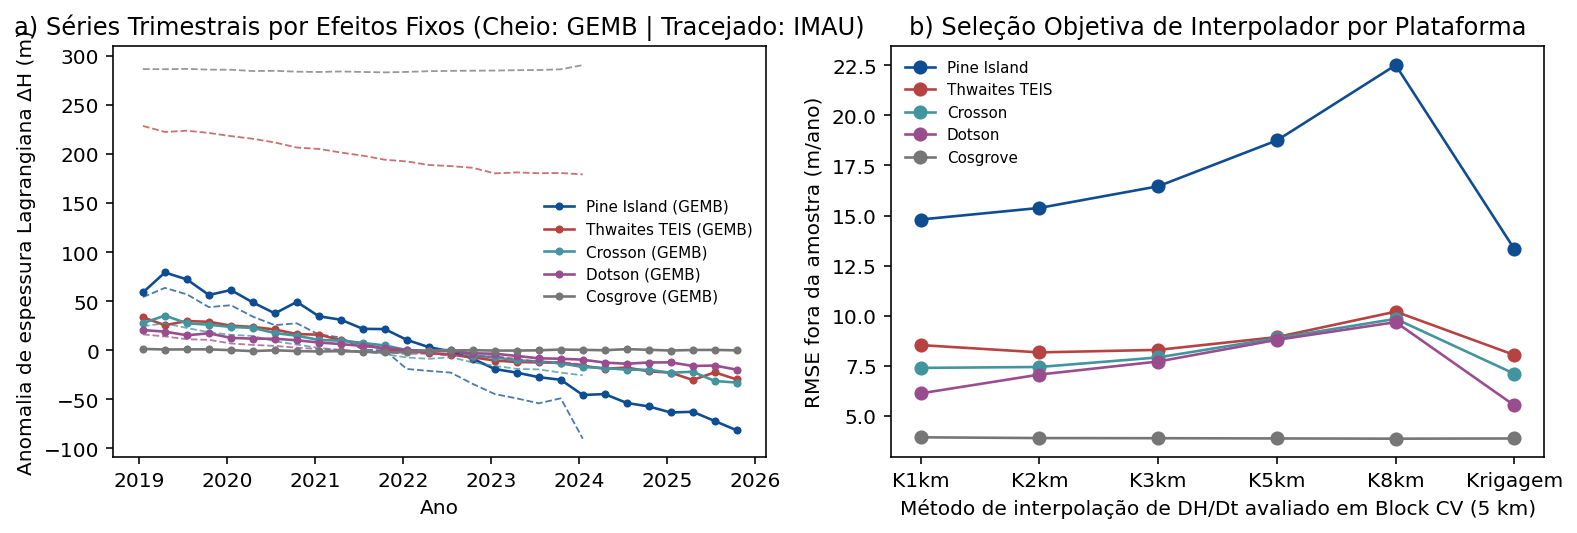

rmse_mpa                               dp_erro_padronizado                             
metodo        kernel_2km kernel_5km kernel_8km    krig          kernel_2km kernel_5km kernel_8km   krig
unidade                                                                                                
Cosgrove           3.874      3.855      3.844   3.853                 NaN        NaN        NaN  0.314
Crosson            7.428      8.868      9.834   7.087                 NaN        NaN        NaN  1.007
Dotson             7.049      8.784      9.668   5.503                 NaN        NaN        NaN  0.892
Pine_Island       15.379     18.754     22.518  13.315                 NaN        NaN        NaN  0.745
Thwaites_TEIS      8.156      8.922     10.194   8.026                 NaN        NaN        NaN  0.994
Thwaites_TWGT     26.444     28.213     31.184  26.149                 NaN        NaN        NaN  0.920

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.8))
colors = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E", "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
for u, col in colors.items():
    sub = ser_h[ser_h["plataforma"] == u].sort_values("t_meio")
    ax[0].plot(sub["t_meio"], sub["dH_lagr_m"], "o-", color=col, lw=1.3, ms=3, label=f"{u.replace('_', ' ')} (GEMB)")
    sub_im = sub[np.isfinite(sub["dH_lagr_imau_m"])]
    ax[0].plot(sub_im["t_meio"], sub_im["dH_lagr_imau_m"], "--", color=col, lw=0.9, alpha=0.75)
ax[0].set_xlabel("Ano")
ax[0].set_ylabel("Anomalia de espessura Lagrangiana ΔH (m)")
ax[0].set_title("a) Séries Trimestrais por Efeitos Fixos (Cheio: GEMB | Tracejado: IMAU)")
ax[0].legend(frameon=False, fontsize=7.5)

piv_cv = cv_krig.pivot(index="unidade", columns="metodo", values="rmse_mpa")
for u, col in colors.items():
    if u in piv_cv.index:
        vals_u = piv_cv.loc[u, ["kernel_1km", "kernel_2km", "kernel_3km", "kernel_5km", "kernel_8km", "krig"]]
        ax[1].plot(["K1km", "K2km", "K3km", "K5km", "K8km", "Krigagem"], vals_u.to_numpy(dtype=float), "o-", color=col, lw=1.3, label=u.replace("_", " "))
ax[1].set_xlabel("Método de interpolação de DH/Dt avaliado em Block CV (5 km)")
ax[1].set_ylabel("RMSE fora da amostra (m/ano)")
ax[1].set_title("b) Seleção Objetiva de Interpolador por Plataforma")
ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout()

cv_krig[cv_krig["metodo"].isin(["kernel_2km", "kernel_5km", "kernel_8km", "krig"])].pivot(
    index="unidade", columns="metodo", values=["rmse_mpa", "dp_erro_padronizado"]
).round(3)

---
## 3. Investigação das Manchas de $m_b < 0$ (*Blue Spots*) e Comparação de Velocidade ITS_LIVE vs. MEaSUREs

Nos mapas de $500\text{ m}$, entre $2{,}3\%$ (Crosson) e $23{,}2\%$ (Cosgrove) dos pixels apresentam $m_b < 0$ aparente. Em vez de rotulá-los acriticamente como "recongelamento marinho basal (*marine ice accretion*)", testamos três hipóteses físicas (`run_blue_spots_ase.py` e `run_open_checks_ase.py`):
1. **Artefato de interpolação de $DH/Dt$?** **Descartado:** A fração de pixels negativos é praticamente idêntica nas células com observação direta do ICESat-2 e nas células interpoladas por krigagem (Dotson: $10{,}6\%$ observado vs. $8{,}7\%$ interpolado; Cosgrove: $21{,}7\%$ vs. $23{,}9\%$);
2. **Ruído de pequena escala na derivada de velocidade $\nabla\cdot\mathbf{u}$ e compensação hidrostática de fendas/canais (Chartrand et al., 2024)?** **Confirmado para a maior parte das manchas:** Ao aumentar a escala do filtro gaussiano de $\nabla\cdot\mathbf{u}$ de $1\text{ km}$ para $5\text{ km}$, a área negativa cai de $9{,}5\%$ para $0{,}96\%$ na Dotson e de $23{,}2\%$ para $6{,}5\%$ na Cosgrove, sem alterar a média da plataforma ($\le 0{,}1\text{ m/ano}$). Além disso, no produto de longo prazo de Paolo et al. (2023, 1992–2017) nos mesmos pixels, essas manchas não aparecem;
3. **Manchas persistentes nas 4 escalas:** Restam apenas duas feições que persistem de $1$ a $5\text{ km}$: a faixa sul da Cosgrove ($3\%$ da área com $m_b + 2\sigma < 0$) e um lobo de $\sim 41\text{ km}^2$ a oeste da Pine Island ($m_b \approx -5\text{ m/ano}$), onde há forte divergência extensional local.

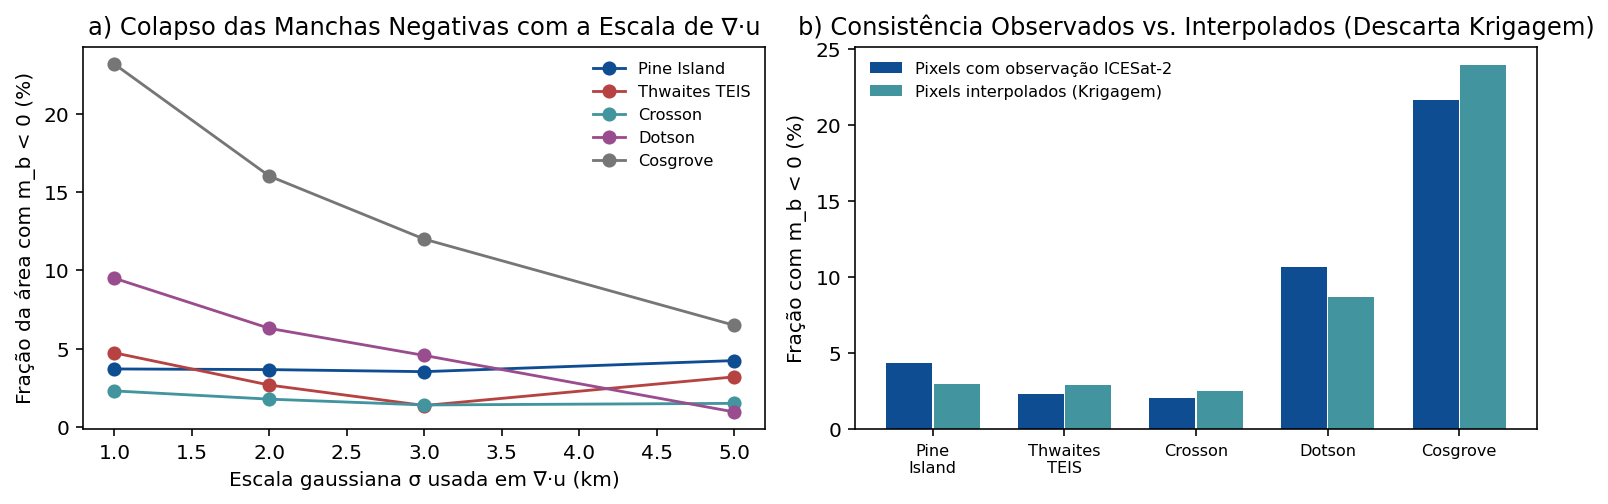

,,frac_dominio,Hdiv_ITS_LIVE_mpa,Hdiv_MEaSUREs_mpa,diferenca_mpa,r_espacial
unidade,escala_km,,,,,
Pine_Island,2,1.0,6.403,5.924,-0.478,0.937
Thwaites_TEIS,2,1.0,2.234,1.734,-0.500,0.859
Crosson,2,1.0,0.975,0.865,-0.110,0.862
Dotson,2,1.0,-0.729,-0.696,0.033,0.824
Cosgrove,2,1.0,-0.158,-0.456,-0.298,0.557
Pine_Island,3,1.0,6.483,5.874,-0.609,0.938
Thwaites_TEIS,3,1.0,2.868,1.876,-0.993,0.748
Crosson,3,1.0,0.978,0.897,-0.081,0.918
Dotson,3,1.0,-0.765,-0.740,0.025,0.876


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
scales_cols = ["frac_neg_div1km", "frac_neg_div2km", "frac_neg_div3km", "frac_neg_div5km"]
for _, row in blue_spots.iterrows():
    u = row["unidade"]
    if u in colors:
        ax[0].plot([1, 2, 3, 5], [100 * row[c] for c in scales_cols], "o-", color=colors[u], lw=1.4, label=u.replace("_", " "))
ax[0].set_xlabel("Escala gaussiana σ usada em ∇·u (km)")
ax[0].set_ylabel("Fração da área com m_b < 0 (%)")
ax[0].set_title("a) Colapso das Manchas Negativas com a Escala de ∇·u")
ax[0].legend(frameon=False, fontsize=8)

x_u = np.arange(len(blue_spots))
ax[1].bar(x_u - 0.18, 100 * blue_spots["frac_neg_em_pix_observados"], width=0.35, color="#0F4D92", label="Pixels com observação ICESat-2")
ax[1].bar(x_u + 0.18, 100 * blue_spots["frac_neg_em_pix_interpolados"], width=0.35, color="#42949E", label="Pixels interpolados (Krigagem)")
ax[1].set_xticks(x_u)
ax[1].set_xticklabels([u.replace("_", "\n") for u in blue_spots["unidade"]], fontsize=8)
ax[1].set_ylabel("Fração com m_b < 0 (%)")
ax[1].set_title("b) Consistência Observados vs. Interpolados (Descarta Krigagem)")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

vel_check.set_index(["unidade", "escala_km"]).round(3)